# EV ChargeOps - Frente 3: motor de rateio (evidência de funcionamento)

Este notebook executa o **motor de rateio** implementado em `backend/rateio/` sobre os casos exigidos pelo
plano da Sprint 2 e mostra, passo a passo, como uma sessão de recarga vira uma linha de fatura auditável.

- Não precisa de banco de dados: o motor é puro (recebe dados, devolve o cálculo).
- O fluxo com PostgreSQL (reserva, anomalia, fatura, fechamento e relatório) está em
  `scripts/demo_frente3.py`, com a saída salva em `evidencias/frente3/demo_output.txt`.
- **Preços, tarifas e alíquotas são fictícios**: na operação real eles vêm da assembleia e do enquadramento
  tributário (Frente 2).

Para executar: a partir da raiz do repositório, `pip install -r requirements-frente3.txt` e abra este arquivo.

In [1]:
import sys
from dataclasses import replace
from datetime import datetime, timedelta
from decimal import Decimal as D
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from backend import config
from backend.db.enums import BAND_LABELS_PT, Band, SessionEndStatus, ValidationStatus
from backend.rateio import (BandPrice, PowerSample, SessionInput, TariffSpec, TaxRuleSpec, TimeWindow,
                            calculate_session, summarize_invoice)
from backend.rateio.money import brl, pt_number
from backend.seeds.demo import DEMO_WINDOWS, TARIFF_V2_PRICES
from backend.seeds.holidays import aneel_national_holidays

TZ = config.CONDO_TIMEZONE
EVIDENCE = ROOT / "evidencias" / "frente3"
EVIDENCE.mkdir(parents=True, exist_ok=True)
HOLIDAYS = frozenset(aneel_national_holidays(2026))
pd.set_option("display.max_colwidth", 120)

# Paleta dos gráficos (surface, tintas de texto e grade recessivas; série única em azul)
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES = "#2a78d6"
BAND_FILL = {Band.OFF_PEAK: "#f6f5f2", Band.INTERMEDIATE: "#e9e8e2", Band.PEAK: "#d6d5cc"}  # ordinal
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})

def at(day, hour, minute=0, month=9):
    return datetime(2026, month, day, hour, minute, tzinfo=TZ)

def session(**kw):
    base = dict(session_id="demo", user_id=1, started_at=at(21, 10), ended_at=at(21, 12), energy_ended_at=at(21, 12),
                total_kwh=D("14"), green_kwh=D("0"), grid_kwh=D("14"), end_status=SessionEndStatus.COMPLETED,
                validation_status=ValidationStatus.APPROVED, charger_rated_power_kw=D("7"))
    base.update(kw)
    return SessionInput(**base)

print("Motor carregado. Fuso do condomínio:", TZ.key)

Motor carregado. Fuso do condomínio: America/Sao_Paulo


## 1. A tabela tarifária (parâmetro da assembleia, não constante no código)

As faixas espelham a Tarifa Branca da ANEEL (Frente 1): ponta das 18h às 21h, intermediário na hora anterior e na
posterior, fora de ponta no restante. Sábados, domingos e os 11 feriados nacionais da lista da ANEEL são fora de
ponta o dia todo. Cada faixa tem **preço Green** (energia solar/bateria) e **preço Grid** (energia da rede).

In [2]:
ISS_DEMO = [TaxRuleSpec("iss", D("5"), id=1, legal_basis="LC 116/2003, item 14.01 (alíquota demonstrativa)")]
tariff = TariffSpec(
    id=2, name="Tabela tarifária 2026 - versão 2 (fictícia)",
    prices={band: BandPrice(green, grid) for band, (green, grid) in TARIFF_V2_PRICES.items()},
    windows=tuple(TimeWindow(b, s, e) for b, s, e in DEMO_WINDOWS),
    idle_tolerance_minutes=15, idle_fee_per_minute=D("0.25"), overhead_percent=D("5"),
    weekends_holidays_off_peak=True,
)
tariff.validate()

schedule = {Band.OFF_PEAK: "00:00-17:00 e 22:00-24:00 (+ fins de semana e feriados)",
            Band.INTERMEDIATE: "17:00-18:00 e 21:00-22:00", Band.PEAK: "18:00-21:00"}
pd.DataFrame([
    {"Faixa": BAND_LABELS_PT[b], "Horário (dias úteis)": schedule[b],
     "Preço Green (R$/kWh)": pt_number(p.green_price_per_kwh, 2), "Preço Grid (R$/kWh)": pt_number(p.grid_price_per_kwh, 2)}
    for b, p in tariff.prices.items()
]).set_index("Faixa")

,Horário (dias úteis),Preço Green (R$/kWh),Preço Grid (R$/kWh)
Faixa,,,
Fora de ponta,00:00-17:00 e 22:00-24:00 (+ fins de semana e feriados),"0,30","0,65"
Intermediário,17:00-18:00 e 21:00-22:00,"0,30","0,95"
Ponta,18:00-21:00,"0,30","1,45"


In [3]:
print(f"Tolerância de ociosidade: {tariff.idle_tolerance_minutes} min | taxa: {brl(tariff.idle_fee_per_minute, 2)}/min")
print(f"Overhead operacional: {pt_number(tariff.overhead_percent, 2)}% do subtotal | imposto de demonstração: ISS 5%")

Tolerância de ociosidade: 15 min | taxa: R$ 0,25/min
Overhead operacional: 5,00% do subtotal | imposto de demonstração: ISS 5%


## 2. Sessão que atravessa faixas (caso obrigatório do plano da Sprint 2)

> *"Se a recarga começa em uma faixa e termina em outra, a cobrança deve ser particionada por intervalo [...]
> Exemplo: 17:30-18:00 = faixa intermediária; 18:00-20:30 = ponta."*

Sessão S8 do cenário de demonstração: segunda-feira, 21/09/2026, carga das 17:30 às 20:30 (19,2 kWh medidos,
0,6 Green e 18,6 Grid) e o carro só é desconectado às 20:50. A curva de potência (leituras a cada 5 min) mostra a
queda de potência no fim da carga, típica quando a bateria se aproxima do nível configurado.

In [4]:
powers = ["6.6"] + ["6.9"] * 30 + ["6.0", "5.0", "4.0", "3.0", "2.0", "0.0", "0.0", "0.0", "0.0", "0.0"]
curve = tuple(PowerSample(at(21, 17, 30) + timedelta(minutes=5 * i), D(p)) for i, p in enumerate(powers))
s8 = session(session_id="S8", started_at=at(21, 17, 30), energy_ended_at=at(21, 20, 30), ended_at=at(21, 20, 50),
             total_kwh=D("19.2"), green_kwh=D("0.6"), grid_kwh=D("18.6"), power_samples=curve)
charge_s8 = calculate_session(s8, tariff, ISS_DEMO, HOLIDAYS, TZ)

segments = charge_s8.calculation["band_split"]["segments"]
print("Método de divisão:", charge_s8.calculation["band_split"]["method_description"])
pd.DataFrame([{
    "Trecho": f"{s['start'][11:16]}-{s['end'][11:16]}", "Faixa": s["band_label"], "Minutos": int(float(s["minutes"])),
    "kWh Green": pt_number(D(s["green_kwh"]), 3), "kWh Grid": pt_number(D(s["grid_kwh"]), 3),
    "Preço Green": brl(D(s["green_price_per_kwh"]), 4), "Preço Grid": brl(D(s["grid_price_per_kwh"]), 4),
    "Valor (R$)": pt_number(D(s["green_value"]) + D(s["grid_value"]), 4),
} for s in segments]).set_index("Trecho")

Método de divisão: Proporção de cada trecho calculada pela curva de potência (integração da potência no tempo).


,Faixa,Minutos,kWh Green,kWh Grid,Preço Green,Preço Grid,Valor (R$)
Trecho,,,,,,,
17:30-18:00,Intermediário,30,"0,107","3,332","R$ 0,3000","R$ 0,9500","3,1975"
18:00-20:30,Ponta,150,"0,493","15,268","R$ 0,3000","R$ 1,4500","22,2865"


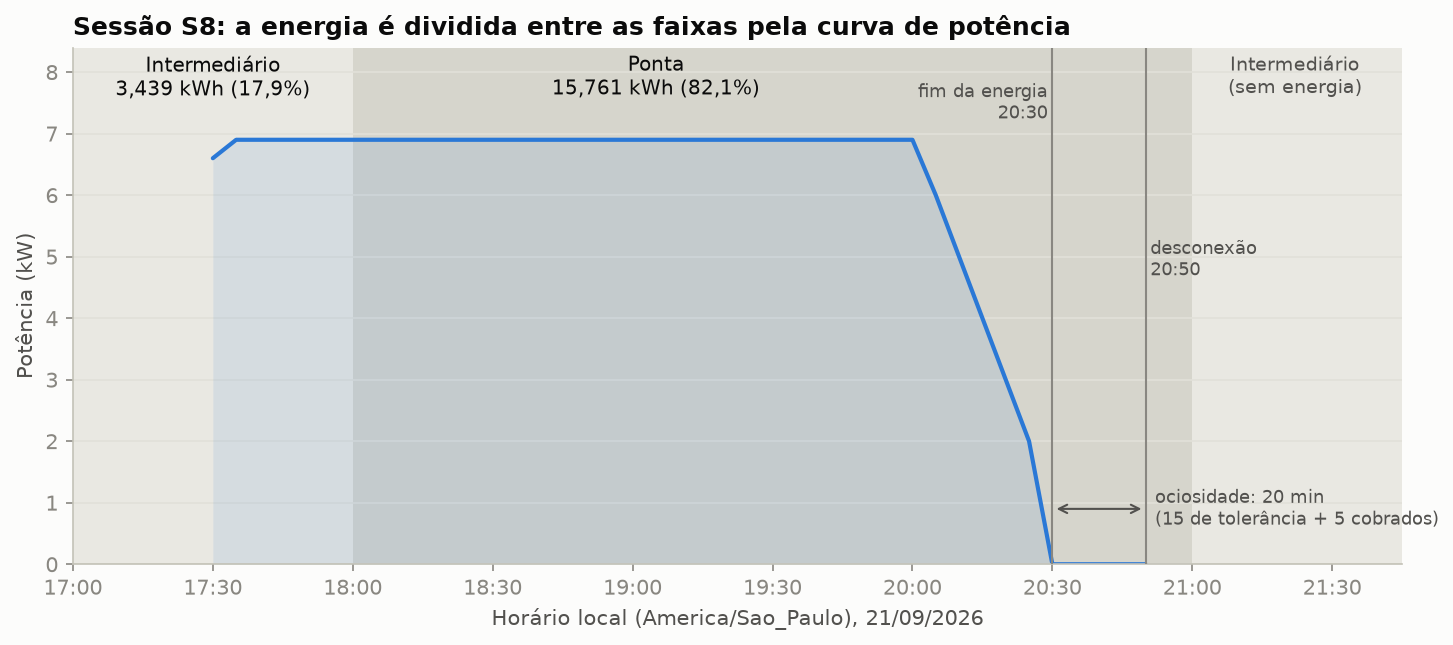

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4), dpi=150)
view_start, view_end = at(21, 17, 0), at(21, 21, 45)
bands_in_view = [(at(21, 17), at(21, 18), Band.INTERMEDIATE), (at(21, 18), at(21, 21), Band.PEAK),
                 (at(21, 21), view_end, Band.INTERMEDIATE)]
for start, end, band in bands_in_view:
    ax.axvspan(start, end, color=BAND_FILL[band], zorder=0, linewidth=0)

times = [s.measured_at for s in curve]
kw = [float(s.power_kw) for s in curve]
ax.fill_between(times, kw, color=SERIES, alpha=0.10, linewidth=0, zorder=1)
ax.plot(times, kw, color=SERIES, linewidth=2, solid_joinstyle="round", solid_capstyle="round", zorder=2)

# rótulo direto de cada faixa, com a energia faturada no trecho (da memória de cálculo)
for seg, x in zip(segments, (at(21, 17, 30), at(21, 19, 5))):
    total = D(seg["green_kwh"]) + D(seg["grid_kwh"])
    share = total / D("19.2") * 100
    ax.text(x, 8.3, f"{seg['band_label']}\n{pt_number(total, 3)} kWh ({pt_number(share, 1)}%)",
            ha="center", va="top", color=INK, fontsize=9.5)
ax.text(at(21, 21, 22, ), 8.3, "Intermediário\n(sem energia)", ha="center", va="top", color=INK_2, fontsize=9)

ax.axvline(at(21, 20, 30), color=MUTED, linewidth=1, zorder=3)
ax.axvline(at(21, 20, 50), color=MUTED, linewidth=1, zorder=3)
ax.text(at(21, 20, 29), 7.15, "fim da energia\n20:30", ha="right", va="bottom", color=INK_2, fontsize=8.5)
ax.text(at(21, 20, 51), 4.6, "desconexão\n20:50", ha="left", va="bottom", color=INK_2, fontsize=8.5)
ax.annotate("", xy=(at(21, 20, 50), 0.9), xytext=(at(21, 20, 30), 0.9),
            arrowprops=dict(arrowstyle="<->", color=INK_2, linewidth=1))
ax.text(at(21, 20, 52), 0.9, "ociosidade: 20 min\n(15 de tolerância + 5 cobrados)", ha="left", va="center",
        color=INK_2, fontsize=8.5)

ax.set_xlim(view_start, view_end)
ax.set_ylim(0, 8.4)
ax.grid(axis="x", visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30], tz=TZ))
ax.set_ylabel("Potência (kW)")
ax.set_xlabel("Horário local (America/Sao_Paulo), 21/09/2026")
ax.set_title("Sessão S8: a energia é dividida entre as faixas pela curva de potência")
fig.tight_layout()
fig.savefig(EVIDENCE / "grafico_sessao_atravessando_faixas.png")
plt.show()

### Por que não usar a tarifa do horário inicial?

O plano proíbe cobrar a sessão inteira pela faixa em que ela começou. Abaixo, o valor da **energia da rede**
(18,6 kWh) da mesma sessão calculado de quatro formas. Cobrar tudo como intermediário subestimaria a conta em
cerca de R$ 7,60, justamente no horário que a tarifa por faixa quer desestimular.

,Energia da rede (R$)
Método,
Tarifa do horário inicial (proibido pelo plano),"R$ 17,67"
Partição pelo tempo (sem curva de potência),"R$ 25,42"
Partição pela curva de potência (usado pelo motor),"R$ 25,30"
Tudo como ponta (limite superior),"R$ 26,97"


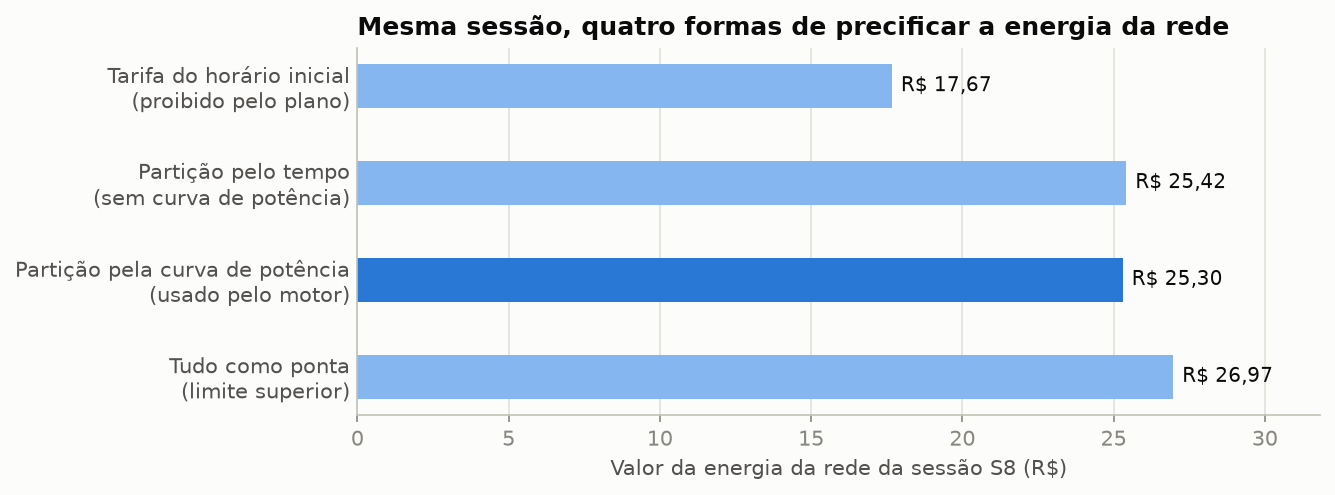

In [6]:
grid_kwh = D("18.6")
p_int = tariff.prices[Band.INTERMEDIATE].grid_price_per_kwh
p_peak = tariff.prices[Band.PEAK].grid_price_per_kwh
by_time = calculate_session(replace(s8, power_samples=()), tariff, [], HOLIDAYS, TZ)  # mesma sessão, sem curva
methods = [
    ("Tarifa do horário inicial\n(proibido pelo plano)", grid_kwh * p_int),
    ("Partição pelo tempo\n(sem curva de potência)", by_time.grid_amount),
    ("Partição pela curva de potência\n(usado pelo motor)", charge_s8.grid_amount),
    ("Tudo como ponta\n(limite superior)", grid_kwh * p_peak),
]
comparison = pd.DataFrame([{"Método": m.replace("\n", " "), "Energia da rede (R$)": brl(v)} for m, v in methods])
display(comparison.set_index("Método"))

fig, ax = plt.subplots(figsize=(9, 3.4), dpi=150)
labels = [m for m, _ in methods][::-1]
values = [float(v) for _, v in methods][::-1]
colors = ["#86b6ef" if "motor" not in m else SERIES for m in labels]
bars = ax.barh(labels, values, color=colors, height=0.45)
for bar, value in zip(bars, values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, brl(D(str(value))),
            va="center", color=INK, fontsize=9.5)
ax.set_xlim(0, max(values) * 1.18)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK_2, length=0)
ax.set_xlabel("Valor da energia da rede da sessão S8 (R$)")
ax.set_title("Mesma sessão, quatro formas de precificar a energia da rede")
fig.tight_layout()
fig.savefig(EVIDENCE / "grafico_metodos_de_precificacao.png")
plt.show()

## 3. Tarifa de ociosidade: critérios de aceite do plano

> *14 min = R$ 0; 15 min = R$ 0; 16 min = 1 min cobrado; falha do sistema = R$ 0.*

Contam-se os minutos completos em que o carro fica na vaga depois do fim do fluxo de energia, menos 15 minutos de
tolerância. Pela regra da Sprint 1, sessões interrompidas (pelo morador ou por falha) não pagam ociosidade.

In [7]:
rows = []
for minutes in (0, 14, 15, 16, 20, 30, 60):
    c = calculate_session(session(ended_at=at(21, 12) + timedelta(minutes=minutes)), tariff, [], HOLIDAYS, TZ)
    rows.append({"Caso": "concluída", "Minutos na vaga após a carga": minutes,
                 "Minutos cobrados": c.idle_minutes, "Ociosidade": brl(c.idle_amount)})
for status, label in ((SessionEndStatus.USER_STOPPED, "encerrada pelo morador"),
                      (SessionEndStatus.SYSTEM_FAILURE, "falha do sistema")):
    c = calculate_session(session(ended_at=at(21, 12) + timedelta(minutes=50), end_status=status),
                          tariff, [], HOLIDAYS, TZ)
    rows.append({"Caso": label, "Minutos na vaga após a carga": 50,
                 "Minutos cobrados": c.idle_minutes, "Ociosidade": brl(c.idle_amount)})
pd.DataFrame(rows)

,Caso,Minutos na vaga após a carga,Minutos cobrados,Ociosidade
0,concluída,0,0,"R$ 0,00"
1,concluída,14,0,"R$ 0,00"
2,concluída,15,0,"R$ 0,00"
3,concluída,16,1,"R$ 0,25"
4,concluída,20,5,"R$ 1,25"
5,concluída,30,15,"R$ 3,75"
6,concluída,60,45,"R$ 11,25"
7,encerrada pelo morador,50,0,"R$ 0,00"
8,falha do sistema,50,0,"R$ 0,00"


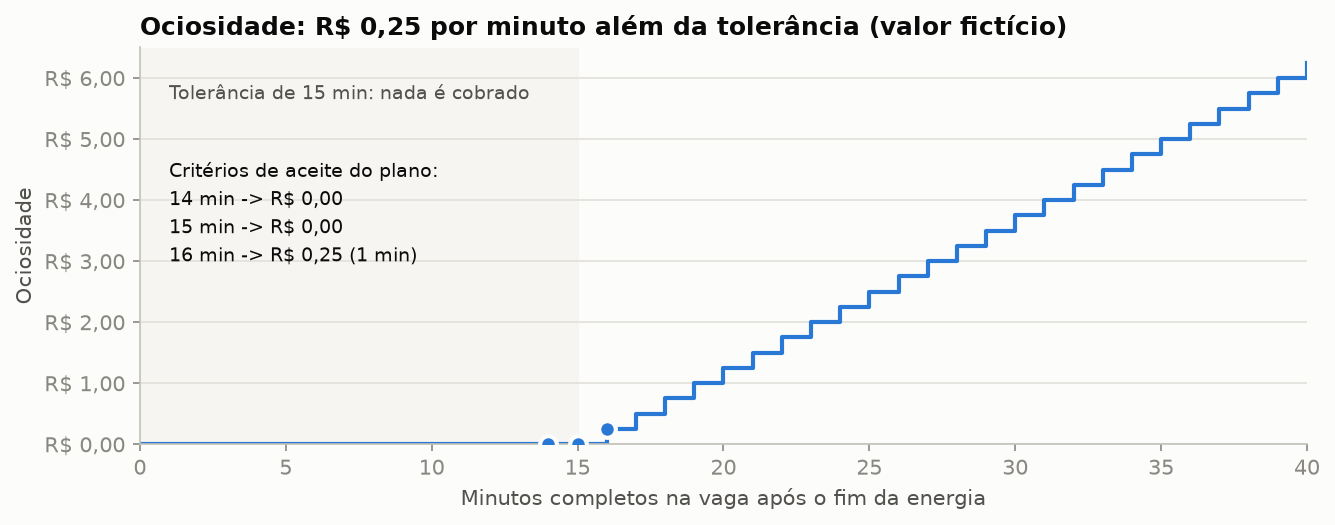

In [8]:
xs = list(range(0, 41))
ys = [max(0, x - 15) * 0.25 for x in xs]
fig, ax = plt.subplots(figsize=(9, 3.6), dpi=150)
ax.axvspan(0, 15, color=BAND_FILL[Band.OFF_PEAK], zorder=0)
ax.step(xs, ys, where="post", color=SERIES, linewidth=2, zorder=2)
for minute in (14, 15, 16):
    ax.scatter([minute], [max(0, minute - 15) * 0.25], s=64, color=SERIES, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.text(1, 5.9, "Tolerância de 15 min: nada é cobrado", ha="left", va="top", color=INK_2, fontsize=9)
ax.text(1, 4.7, "Critérios de aceite do plano:\n14 min -> R$ 0,00\n15 min -> R$ 0,00\n16 min -> R$ 0,25 (1 min)",
        ha="left", va="top", color=INK, fontsize=9, linespacing=1.5)
ax.set_xlim(0, 40)
ax.set_ylim(0, 6.5)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Minutos completos na vaga após o fim da energia")
ax.set_ylabel("Ociosidade")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"R$ {v:.2f}".replace(".", ",")))
ax.set_title("Ociosidade: R$ 0,25 por minuto além da tolerância (valor fictício)")
fig.tight_layout()
fig.savefig(EVIDENCE / "grafico_ociosidade.png")
plt.show()

## 4. Imposto parametrizável (Frente 2)

A Frente 2 mostrou que o tributo da recarga está em disputa (ICMS x ISS) e em transição (IBS/CBS). Por isso o
imposto é um **parâmetro com vigência**, e podem valer vários ao mesmo tempo. A exclusão da energia compensada da
base (LC 214/2025, art. 28; Decreto 12.955/2026, art. 15) é um interruptor por regra, ligado só quando a modalidade
de geração permitir. **As alíquotas abaixo são ilustrativas.**

In [9]:
scenarios = {
    "ISS 5% (demonstração)": [TaxRuleSpec("iss", D("5"))],
    "ICMS 18% (tese estadual)": [TaxRuleSpec("icms", D("18"))],
    "CBS 0,9% + IBS 0,1% (ilustrativo)": [TaxRuleSpec("cbs", D("0.9")), TaxRuleSpec("ibs", D("0.1"))],
    "CBS 10% excluindo energia compensada": [TaxRuleSpec("cbs", D("10"), exclude_compensated_energy=True)],
    "CBS 10% sem exclusão": [TaxRuleSpec("cbs", D("10"))],
}
solar = session(started_at=at(9, 10), energy_ended_at=at(9, 13), ended_at=at(9, 13, 14),  # sessão S2 (sol)
                total_kwh=D("18"), green_kwh=D("12.5"), grid_kwh=D("5.5"))
rows = []
for name, rules in scenarios.items():
    c = calculate_session(solar, tariff, rules, HOLIDAYS, TZ)
    taxes = c.calculation["components"]["taxes"]
    rows.append({"Cenário": name, "Subtotal": brl(c.subtotal),
                 "Base de cada imposto": " / ".join(brl(D(t["base"])) for t in taxes),
                 "Imposto": brl(c.tax_amount), "Total": brl(c.total)})
pd.DataFrame(rows).set_index("Cenário")

,Subtotal,Base de cada imposto,Imposto,Total
Cenário,,,,
ISS 5% (demonstração),"R$ 7,33","R$ 7,33","R$ 0,37","R$ 8,07"
ICMS 18% (tese estadual),"R$ 7,33","R$ 7,33","R$ 1,32","R$ 9,02"
"CBS 0,9% + IBS 0,1% (ilustrativo)","R$ 7,33","R$ 7,33 / R$ 7,33","R$ 0,08","R$ 7,78"
CBS 10% excluindo energia compensada,"R$ 7,33","R$ 3,58","R$ 0,36","R$ 8,06"
CBS 10% sem exclusão,"R$ 7,33","R$ 7,33","R$ 0,73","R$ 8,43"


## 5. Casos excepcionais da Sprint 1 (seção 6.4)

In [10]:
failure = calculate_session(session(end_status=SessionEndStatus.SYSTEM_FAILURE, failure_code="E-COMM"),
                            tariff, ISS_DEMO, HOLIDAYS, TZ)
stopped = calculate_session(session(end_status=SessionEndStatus.USER_STOPPED, ended_at=at(21, 13)),
                            tariff, ISS_DEMO, HOLIDAYS, TZ)
normal = calculate_session(session(ended_at=at(21, 13)), tariff, ISS_DEMO, HOLIDAYS, TZ)
ana = summarize_invoice([normal])
bruno = summarize_invoice([stopped])
carla = summarize_invoice([])
pd.DataFrame([
    {"Caso": "Sessão interrompida por falha do sistema", "Resultado": f"linha de {brl(failure.total)} com o motivo",
     "Regra": failure.charge_rule},
    {"Caso": "Sessão encerrada pelo morador (1 h na vaga)", "Resultado": f"só energia: {brl(stopped.total)}",
     "Regra": stopped.charge_rule},
    {"Caso": "Mesma sessão concluída normalmente", "Resultado": f"energia + 45 min de ociosidade: {brl(normal.total)}",
     "Regra": normal.charge_rule},
    {"Caso": "Morador que não carregou no mês", "Resultado": f"fatura de {brl(carla.total)}, sem mínimo",
     "Regra": "summarize_invoice([])"},
    {"Caso": "Dois veículos da mesma unidade", "Resultado": f"duas faturas: {brl(ana.total)} e {brl(bruno.total)}",
     "Regra": "uma fatura por morador"},
    {"Caso": "No-show de reserva", "Resultado": "sem sessão, sem cobrança (bloqueio é regra do backend)",
     "Regra": "-"},
]).set_index("Caso")

,Resultado,Regra
Caso,,
Sessão interrompida por falha do sistema,"linha de R$ 0,00 com o motivo",system_failure_no_charge
Sessão encerrada pelo morador (1 h na vaga),"só energia: R$ 10,02",user_stopped_no_idle
Mesma sessão concluída normalmente,"energia + 45 min de ociosidade: R$ 22,39",normal
Morador que não carregou no mês,"fatura de R$ 0,00, sem mínimo",summarize_invoice([])
Dois veículos da mesma unidade,"duas faturas: R$ 22,39 e R$ 10,02",uma fatura por morador
No-show de reserva,"sem sessão, sem cobrança (bloqueio é regra do backend)",-


## 6. Memória de cálculo auditável (LGPD art. 20)

Cada linha da fatura guarda uma memória de cálculo em JSON (coluna `invoice_items.calculation`): a cópia da
tarifa usada, os trechos por faixa, as fórmulas e um texto explicativo para o morador. A célula seguinte **recalcula
o valor só a partir da memória** e confere com o que o motor gravou (item do checklist: "memória de cálculo
permite reproduzir o valor").

In [11]:
for line in charge_s8.calculation["explanation"]:
    print(line)

Trecho 1: 21/09 17:30-18:00 (Intermediário, dia útil): 0,107 kWh Green x R$ 0,3000 + 3,332 kWh Grid x R$ 0,9500 = R$ 3,1975
Trecho 2: 21/09 18:00-20:30 (Ponta, dia útil): 0,493 kWh Green x R$ 0,3000 + 15,268 kWh Grid x R$ 1,4500 = R$ 22,2865
Energia verde (solar/bateria): R$ 0,18
Energia da rede: R$ 25,30
Ociosidade: 20 min após o fim da carga - 15 min de tolerância = 5 min x R$ 0,2500 = R$ 1,25
Subtotal: R$ 26,73
ISS 5,000% sobre R$ 26,73: R$ 1,34
Overhead operacional 5,00% sobre o subtotal: R$ 1,34
Total da sessão: R$ 29,41


In [12]:
from decimal import ROUND_HALF_UP

def cents(value):
    return value.quantize(D("0.01"), rounding=ROUND_HALF_UP)

memory = charge_s8.calculation
comp = memory["components"]
segs = memory["band_split"]["segments"]
green = cents(sum(D(s["green_kwh"]) * D(s["green_price_per_kwh"]) for s in segs))
grid = cents(sum(D(s["grid_kwh"]) * D(s["grid_price_per_kwh"]) for s in segs))
idle = cents(comp["idle"]["billable_minutes"] * D(comp["idle"]["fee_per_minute"]))
subtotal = green + grid + idle
tax = sum(cents(D(t["base"]) * D(t["rate_percent"]) / 100) for t in comp["taxes"])
overhead = cents(subtotal * D(comp["overhead"]["percent"]) / 100)
recomputed = subtotal + tax + overhead

assert (green, grid, idle, tax, overhead) == (charge_s8.green_amount, charge_s8.grid_amount, charge_s8.idle_amount,
                                             charge_s8.tax_amount, charge_s8.overhead_amount)
assert recomputed == charge_s8.total
print(f"Recalculado a partir da memória: {brl(recomputed)} | gravado pelo motor: {brl(charge_s8.total)} -> confere")

Recalculado a partir da memória: R$ 29,41 | gravado pelo motor: R$ 29,41 -> confere


In [13]:
import json
excerpt = {k: memory[k] for k in ("engine_version", "rule", "band_split")}
excerpt["components"] = {k: memory["components"][k] for k in ("green", "grid", "idle", "taxes", "overhead", "total")}
print(json.dumps(excerpt, indent=2, ensure_ascii=False)[:3000])

{
  "engine_version": "1.0.0",
  "rule": {
    "code": "normal",
    "description": "Sessão concluída normalmente: cobra-se a energia (Green + Grid) e a ociosidade após a tolerância."
  },
  "band_split": {
    "method": "power_curve",
    "method_description": "Proporção de cada trecho calculada pela curva de potência (integração da potência no tempo).",
    "segments": [
      {
        "index": 1,
        "start": "2026-09-21T17:30:00-03:00",
        "end": "2026-09-21T18:00:00-03:00",
        "minutes": "30.0",
        "band": "intermediate",
        "band_label": "Intermediário",
        "day_type": "dia útil",
        "green_kwh": "0.107",
        "grid_kwh": "3.332",
        "green_price_per_kwh": "0.3000",
        "grid_price_per_kwh": "0.9500",
        "green_value": "0.032100",
        "grid_value": "3.165400"
      },
      {
        "index": 2,
        "start": "2026-09-21T18:00:00-03:00",
        "end": "2026-09-21T20:30:00-03:00",
        "minutes": "150.0",
        "band

## 7. Fatura mensal da Ana (setembro/2026)

A fatura soma as sessões válidas do morador. Estas são as mesmas três sessões da Ana no cenário do banco
(`scripts/demo_frente3.py`), e o total precisa bater com o gerado lá: **R$ 43,54**.

In [14]:
s1 = session(session_id="S1", started_at=at(7, 18, 30), energy_ended_at=at(7, 20), ended_at=at(7, 20, 10),
             total_kwh=D("9"), green_kwh=D("1"), grid_kwh=D("8"))           # feriado da Independência
s2 = session(session_id="S2", started_at=at(9, 10), energy_ended_at=at(9, 13), ended_at=at(9, 13, 14),
             total_kwh=D("18"), green_kwh=D("12.5"), grid_kwh=D("5.5"))     # ociosidade de 14 min
charges = [calculate_session(s, tariff, ISS_DEMO, HOLIDAYS, TZ) for s in (s1, s2, s8)]
invoice = summarize_invoice(charges)

table = pd.DataFrame([{
    "Sessão": c.session_id, "Energia verde": brl(c.green_amount), "Energia da rede": brl(c.grid_amount),
    "Ociosidade": brl(c.idle_amount), "Subtotal": brl(c.subtotal), "Imposto": brl(c.tax_amount),
    "Overhead": brl(c.overhead_amount), "Total": brl(c.total)} for c in charges]
    + [{"Sessão": "FATURA", "Energia verde": brl(invoice.green_amount), "Energia da rede": brl(invoice.grid_amount),
        "Ociosidade": brl(invoice.idle_amount), "Subtotal": brl(invoice.subtotal), "Imposto": brl(invoice.tax_amount),
        "Overhead": brl(invoice.overhead_amount), "Total": brl(invoice.total)}])
assert invoice.total == D("43.54")
table.set_index("Sessão")

,Energia verde,Energia da rede,Ociosidade,Subtotal,Imposto,Overhead,Total
Sessão,,,,,,,
S1,"R$ 0,30","R$ 5,20","R$ 0,00","R$ 5,50","R$ 0,28","R$ 0,28","R$ 6,06"
S2,"R$ 3,75","R$ 3,58","R$ 0,00","R$ 7,33","R$ 0,37","R$ 0,37","R$ 8,07"
S8,"R$ 0,18","R$ 25,30","R$ 1,25","R$ 26,73","R$ 1,34","R$ 1,34","R$ 29,41"
FATURA,"R$ 4,23","R$ 34,08","R$ 1,25","R$ 39,56","R$ 1,99","R$ 1,99","R$ 43,54"


## Conclusão

O notebook demonstrou, com o código real do motor:

1. a partição da sessão por faixa horária (exemplo do plano), com a energia distribuída pela curva de potência;
2. a diferença entre partir a sessão e usar a tarifa do horário inicial;
3. a tolerância de 15 minutos da ociosidade (14, 15 e 16 minutos) e sua não aplicação a sessões interrompidas;
4. o imposto como parâmetro (vários tributos, exclusão da energia compensada como interruptor);
5. os casos excepcionais da Sprint 1;
6. a memória de cálculo que reproduz o valor cobrado;
7. a fatura mensal fechando com o valor gerado pelo fluxo com banco de dados.

As regras de integridade no PostgreSQL (fatura fechada imutável, sessão cobrada uma única vez, tarifas versionadas,
auditoria de anomalias) são demonstradas pelos testes em `backend/tests/db/` e por `scripts/demo_frente3.py`.